# Starting XI — manager picks data profile (2026-27, GW1–7)

A profile of the real-manager panel captured for Stage 5 (fpl-ingest #100/#102/#116), read from the
fpl-warehouse served tables `fct_manager_gameweek` and `fct_manager_pick`, with rank from the raw
entry-picks payloads. Card: [`CARD.md`](CARD.md) §5.

**Exploration only.** Nothing here scores the D2 rule, any rule, or a manager's XI, and nothing
compares a rule with a manager. The Stage 5 definitions are not yet recorded on
[fpl-intelligence#55](https://github.com/gisaf22/fpl-intelligence/issues/55), so pre-registration
stays intact: the two screens are reported as counts, with no outcome attached.

All calculations are in [`picks_profile.py`](picks_profile.py), tested in
`tests/decisions/starting_xi/test_picks_profile.py`; this notebook only presents.

**Summary** — filled in from the outputs below:

1. **Coverage:** 1,998 managers (1,996 random, 2 self), 13,090 manager-weeks, rising from 1,586 in
   GW1 to 1,998 in GW7 as late joiners appear (412 joined after GW1). No manager has a gap.
2. **Auto-subs** touched 37–68% of manager-weeks (62% in GW7); **chips** were played in 8.5–29%
   (Triple Captain peaked at 15.6% in GW3); Free Hit and Bench Boost weeks, which Stage 5 drops,
   are 4.8% of manager-weeks.
3. **Transfers:** outside Wildcard and Free Hit weeks, 38–56% of manager-weeks made at least one;
   the median is 0 or 1.
4. **Ranks:** 30 captures have no rank: the 3 nulls and 27 zeros, all belonging to 6 random-cohort managers
   who drop out of FPL's ranking and stay out. 1,992 managers have a GW7 rank.
5. **Screens (counts only):** 1,498 of 1,920 evaluable managers changed something in GW5–7; 422
   changed nothing. Latest rank inside the top 10k / 100k / 1m: 1 / 27 / 212.
6. **Representativeness:** the panel is not uniform over rank deciles (χ² = 20.9, 9 df, p = 0.013,
   denominator GW7 `ranked_count`). Decile 1 is over-weighted (241 vs
   199 expected). Late joiners fill deciles 9–10, where the GW1 entrants are scarce.

### Setup

**What:** loads the local copy of the served picks tables, every raw picks payload's
`entry_history.overall_rank`, and one bootstrap-static payload for each gameweek's `ranked_count`.
**Why:** every table and chart below reads from these objects.
**How:** `picks_profile.load(DATA_ROOT)`. The copy is git-ignored and synced read-only with
`aws s3 cp` from `s3://fpl-data-safari/served/` (publish `39843421959`),
`raw/fpl/entry-picks/2026-27/` (payloads only) and the 2026-10-22 19:12 UTC bootstrap-static
capture, after GW7 was ranked and before the GW8 deadline.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from decisions.starting_xi import picks_profile as pp

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e1", "axes.axisbelow": True})

data = pp.load(pp.DATA_ROOT)
gw = data.gameweeks
LAST_GW = int(gw["gameweek"].max())
cover = pp.coverage(gw)
print(f"{len(gw):,} manager-weeks, {gw['entry_id'].nunique():,} managers, GW{gw['gameweek'].min()}-{LAST_GW}; "
      f"{len(data.picks):,} picks; {len(data.ranks):,} raw rank rows")

13,090 manager-weeks, 1,998 managers, GW1-7; 196,350 picks; 13,090 raw rank rows


## (a) Who is in the panel, week by week

**What:** manager-weeks captured per gameweek, split into managers present the week before and
managers new that week, plus the cohort split.
**Why:** Stage 5's sample size per gameweek is this table; late joiners have no earlier weeks to
compare against.
**How:** a manager-week is one captured `(entry_id, gameweek)`. A manager is *new* in their first
captured week (the earlier weeks were the expected 404s of a team that did not exist yet).
`random` is the 2,000-ID uniform draw (1,996 kept), `self` the two IDs held outside it.

In [2]:
cover

cohort,manager_weeks_random,manager_weeks_self,manager_weeks,new_managers,managers_to_date
gameweek,,,,,
1,1584,2,1586,1586,1586
2,1780,2,1782,196,1782
3,1866,2,1868,86,1868
4,1918,2,1920,52,1920
5,1947,2,1949,29,1949
6,1985,2,1987,38,1987
7,1996,2,1998,11,1998


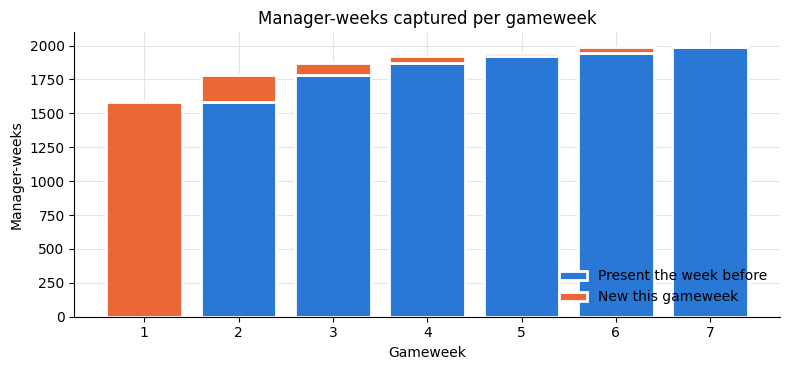

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
returning = cover["manager_weeks"] - cover["new_managers"]
ax.bar(cover.index, returning, color=BLUE, edgecolor="white", linewidth=2, label="Present the week before")
ax.bar(cover.index, cover["new_managers"], bottom=returning, color=ORANGE, edgecolor="white", linewidth=2,
       label="New this gameweek")
ax.set_xlabel("Gameweek"); ax.set_ylabel("Manager-weeks")
ax.set_title("Manager-weeks captured per gameweek")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()

In [4]:
print("Managers with a gap between first and last capture:", len(pp.gaps(gw)))
gw.groupby("entry_id")["cohort"].first().value_counts().rename("managers").to_frame()

Managers with a gap between first and last capture: 0


,managers
cohort,
random,1996
self,2


## (b) Automatic substitutions

**What:** the share of manager-weeks in which FPL made at least one automatic substitution.
**Why:** Stage 5's metric scores the chosen XI *with* auto-subs (CARD §1), so this is how often
the sub rules touch the score at all.
**How:** a manager-week counts if its `automatic_subs` list is non-empty. Cross-checked against
the picks' `is_auto_sub_in` flags: the two agree on every manager-week.

In [5]:
subs = pp.auto_sub_share(gw)
flags = data.picks.groupby(["entry_id", "gameweek"])["is_auto_sub_in"].any()
listed = gw.set_index(["entry_id", "gameweek"])["automatic_subs"].map(len) > 0
print("manager-weeks where the list and the flags disagree:", int((flags.reindex(listed.index) != listed).sum()))
subs.assign(share=(subs["share"] * 100).round(1)).rename(columns={"share": "share_%"})

manager-weeks where the list and the flags disagree: 0


,manager_weeks,with_auto_sub,share_%
gameweek,,,
1,1586,809,51.0
2,1782,657,36.9
3,1868,692,37.0
4,1920,704,36.7
5,1949,1326,68.0
6,1987,1137,57.2
7,1998,1238,62.0


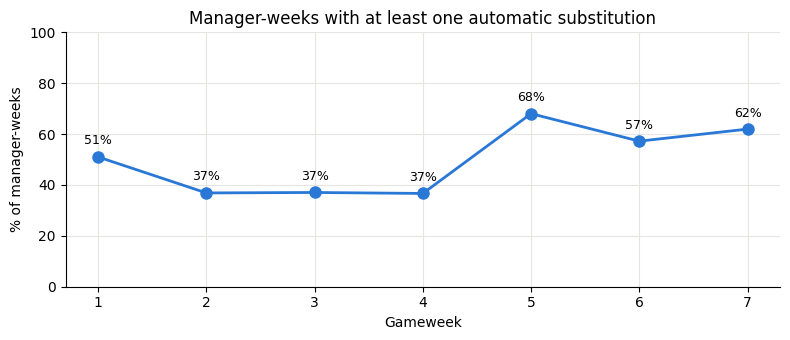

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(subs.index, subs["share"] * 100, color=BLUE, linewidth=2, marker="o", markersize=8)
for g, s in subs["share"].items():
    ax.annotate(f"{s:.0%}", (g, s * 100), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set_ylim(0, 100); ax.set_xlabel("Gameweek"); ax.set_ylabel("% of manager-weeks")
ax.set_title("Manager-weeks with at least one automatic substitution")
plt.tight_layout()

## (c) Chips

**What:** the share of manager-weeks playing each chip.
**Why:** Stage 5 excludes Free Hit and Bench Boost weeks (CARD §5), so their share is sample lost;
Triple Captain and Wildcard weeks stay in.
**How:** `active_chip` per manager-week; *none* is a week without a chip.

In [7]:
chips = pp.chip_share(gw)
(chips * 100).round(1).add_suffix(" %")

active_chip,3xc %,bboost %,freehit %,wildcard %,none %
gameweek,,,,,
1,2.6,10.3,0.0,0.0,87.1
2,2.2,3.2,1.0,2.1,91.5
3,15.6,1.3,4.4,7.5,71.1
4,3.6,1.6,3.5,6.6,84.6
5,1.9,1.3,2.0,5.2,89.5
6,0.9,1.2,1.9,6.6,89.4
7,8.0,1.8,1.0,3.1,86.3


Free Hit or Bench Boost manager-weeks (Stage 5 exclusion): 624 of 13,090 (4.8%)


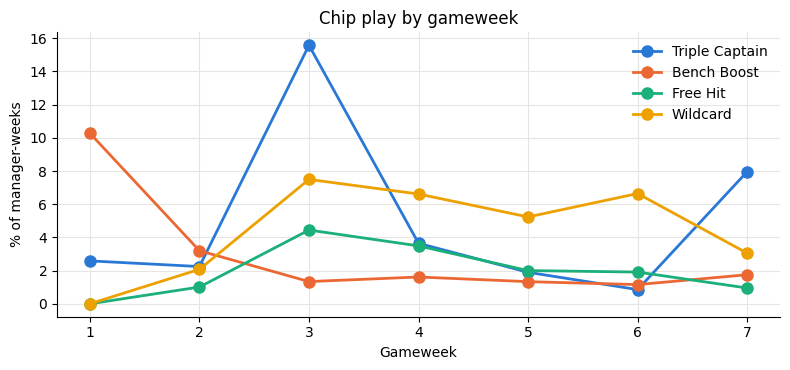

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.8))
names = {"3xc": "Triple Captain", "bboost": "Bench Boost", "freehit": "Free Hit", "wildcard": "Wildcard"}
for chip, colour in zip(pp.CHIPS, (BLUE, ORANGE, AQUA, YELLOW)):
    ax.plot(chips.index, chips[chip] * 100, color=colour, linewidth=2, marker="o", markersize=8, label=names[chip])
ax.set_xlabel("Gameweek"); ax.set_ylabel("% of manager-weeks")
ax.set_title("Chip play by gameweek")
ax.legend(frameon=False)
plt.tight_layout()
excluded = gw["active_chip"].isin(["freehit", "bboost"])
print(f"Free Hit or Bench Boost manager-weeks (Stage 5 exclusion): {int(excluded.sum()):,} of {len(gw):,} "
      f"({excluded.mean():.1%})")

## (d) Transfers

**What:** manager-weeks by transfers made, the number taking a points hit, and a per-gameweek
summary.
**Why:** transfers are the main way a squad changes between weeks; GW1 is squad creation, so it is
0 by definition.
**How:** `event_transfers` bucketed 0 / 1 / 2 / 3 / 4+. Weeks under a Wildcard or Free Hit have
unlimited free transfers, so they are counted in their own column and left out of the summary.
*took_hit* counts weeks with `event_transfers_cost > 0`.

In [9]:
pp.transfers_distribution(gw)

event_transfers,0,1,2,3,4+,wildcard/free hit,took_hit
gameweek,,,,,,,
1,1586,0,0,0,0,0,0
2,1079,441,90,44,73,55,207
3,729,392,354,79,91,223,262
4,884,431,230,102,79,194,213
5,925,459,256,83,85,141,226
6,1054,379,217,93,74,170,175
7,1134,377,254,85,68,80,184


In [10]:
pp.transfers_summary(gw).round(2)

,manager_weeks,mean,median,max,share_any
gameweek,,,,,
1,1586,0.00,0.0,0,0.00
2,1727,0.72,0.0,20,0.38
3,1645,1.18,1.0,20,0.56
4,1726,0.99,0.0,20,0.49
5,1808,0.96,0.0,18,0.49
6,1817,0.85,0.0,17,0.42
7,1918,0.80,0.0,20,0.41


## (e) Captures without a rank

**What:** manager-weeks whose raw `entry_history.overall_rank` is not a rank.
**Why:** the rank screen and the representativeness check need a rank per manager.
**How:** FPL reports an unranked team two ways: `null` (3 captures) and `0` (27 captures). Both
are treated as unranked. All 30 belong to 6 random-cohort managers; the table shows each one's
rank history.

In [11]:
missing = pp.unranked(data.ranks)
print(missing.groupby("kind").size().to_dict(), "across", missing["entry_id"].nunique(), "managers")
history = data.ranks[data.ranks["entry_id"].isin(missing["entry_id"])]
shown = history.assign(overall_rank=history["overall_rank"].map(lambda r: "null" if pd.isna(r) else f"{int(r):,}"))
shown.pivot(index="entry_id", columns="gameweek", values="overall_rank").fillna("not captured")

{'null': 3, 'zero': 27} across 6 managers


gameweek,1,2,3,4,5,6,7
entry_id,,,,,,,
477462,"8,629,327","7,975,773","8,200,205",0,null,0,0
1276382,"7,960,655",0,0,null,0,0,0
1471061,0,0,0,0,0,0,0
2051527,0,0,0,0,0,0,0
2656519,"4,383,525","2,890,221","4,106,209","3,816,159","1,735,975",0,0
10505691,not captured,not captured,not captured,0,null,0,0


## (f) Activity screen — counts only

**What:** how many managers changed anything in the last 3 gameweeks: their picked XI, their
captain, made a transfer, or played a chip.
**Why:** a screen Stage 5 might use to drop abandoned teams. Counts only: no outcome is attached.
**How:** for each of GW5–7 against the week before. The XI is the XI as *picked*: served `slot`
is the lineup after auto-subs, so `picked_xi` swaps the subs back; without that, an auto-sub alone
looks like a lineup change. A manager needs a capture in every week GW4–7 to be evaluable. The
components overlap, so they do not sum to *passes*.

In [12]:
screen = pp.activity_screen(gw, data.picks, LAST_GW)
counts = pp.activity_counts(screen)
share = (counts / counts["evaluable"] * 100).round(1).where(counts.index != "managers")
counts.to_frame().assign(**{"% of evaluable": share})

,managers,% of evaluable
managers,1998,NaN
evaluable,1920,100.0
changed_xi,1483,77.2
changed_captain,966,50.3
transferred,1324,69.0
chip,562,29.3
passes,1498,78.0
fails,422,22.0


## (g) Rank screen — counts only

**What:** how many managers' latest overall rank is inside the top 10k, 100k and 1m.
**Why:** a second candidate screen; counts only, no outcome attached, and no cut-off chosen here.
**How:** each manager's rank in their last captured gameweek (GW7 for all 1,998). The 6 unranked
managers are excluded, never given an older rank. *expected_if_uniform* is the count a uniform
draw over the GW7 ranked population would give.

In [13]:
latest = pp.latest_ranks(data.ranks)
ranked = latest[latest["ranked"]]
N7 = data.ranked_counts[LAST_GW]
screen_counts = pp.rank_screen_counts(latest).to_frame()
screen_counts["expected_if_uniform"] = [round(len(ranked) * t / N7, 1) for t in screen_counts.index]
print(f"ranked managers: {len(ranked):,} of {len(latest):,}")
screen_counts

ranked managers: 1,992 of 1,998


,managers,expected_if_uniform
10000,1,1.8
100000,27,18.0
1000000,212,180.1


## (h) Is the panel representative? Rank-percentile deciles

**What:** how the panel's latest ranks spread over the ten rank-percentile deciles (1 = best 10%),
with a chi-square test against an even spread.
**Why:** a uniform random draw of managers would put 10% in each decile. A skew says which kind of
manager the panel over- or under-weights.
**How:** decile = ⌈10 × overall_rank / N⌉, with N the GW7 `ranked_count` (11,063,261: the teams
GW7's overall ranks are taken over). `total_players` is not used: it also counts teams with no
rank. Standing is `overall_rank` only; the per-gameweek rank ranks one week's points. Chi-square goodness of fit on the counts, 9 degrees of freedom. The random cohort
alone is shown too, since the self cohort is not drawn.

In [14]:
cohort = gw.groupby("entry_id")["cohort"].first()
rows, tests = {}, {}
for subset, frame in [("panel", ranked), ("random only", ranked[ranked["entry_id"].map(cohort) == "random"])]:
    t = pp.decile_uniformity(pp.rank_deciles(frame["overall_rank"], N7))
    rows[subset] = t.counts
    tests[subset] = {"managers": int(t.counts.sum()), "chi_square": round(t.statistic, 1),
                     "dof": t.dof, "p_value": round(t.p_value, 4)}
pd.DataFrame(tests).T.astype({"managers": int, "dof": int})

,managers,chi_square,dof,p_value
panel,1992,20.9,9,0.0133
random only,1990,20.5,9,0.0148


In [15]:
pd.DataFrame(rows).T.rename_axis(columns="decile")

decile,1,2,3,4,5,6,7,8,9,10
panel,241,172,174,208,190,222,208,185,201,191
random only,240,172,174,208,190,222,208,185,201,190


decile,1,2,3,4,5,6,7,8,9,10
joined after GW1,,,,,,,,,,
GW1,241,171,173,201,178,200,183,137,84,13
after GW1,0,1,1,7,12,22,25,48,117,178


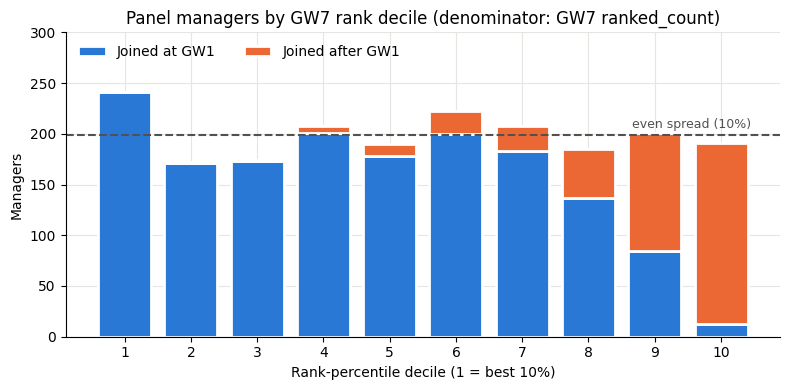

In [16]:
deciles = pp.rank_deciles(ranked["overall_rank"], N7)
first_gw = gw.groupby("entry_id")["gameweek"].min()
late = ranked["entry_id"].map(first_gw).gt(1).to_numpy()
by_join = pd.crosstab(pd.Series(late, name="joined after GW1").map({False: "GW1", True: "after GW1"}),
                      pd.Series(deciles.to_numpy(), name="decile")).reindex(columns=range(1, 11), fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_join.columns, by_join.loc["GW1"], color=BLUE, edgecolor="white", linewidth=2, label="Joined at GW1")
ax.bar(by_join.columns, by_join.loc["after GW1"], bottom=by_join.loc["GW1"], color=ORANGE, edgecolor="white",
       linewidth=2, label="Joined after GW1")
ax.axhline(len(ranked) / 10, color="#52514e", linewidth=1.5, linestyle="--")
ax.annotate("even spread (10%)", (10.45, len(ranked) / 10 + 4), va="bottom", ha="right", fontsize=9, color="#52514e")
ax.set_xticks(range(1, 11)); ax.set_xlabel("Rank-percentile decile (1 = best 10%)"); ax.set_ylabel("Managers")
ax.set_title("Panel managers by GW7 rank decile (denominator: GW7 ranked_count)")
ax.set_ylim(0, 300)
ax.legend(frameon=False, loc="upper left", ncols=2)
plt.tight_layout()
by_join